# 05 · Seed averaging, extra models, ensemble and final submission

**Starting point** (`04_tuning`, 15-fold CV on train+valid): tuned CatBoost **0.7118**, tuned LightGBM 0.7058, 41 features.

**Plan**
1. **Seed averaging:** refit the tuned CatBoost and LightGBM with 5 model seeds each (same folds, same tree count) and average. Cheap, and removes some of the randomness from bagging/feature sampling.
2. **XGBoost:** a third GBM, briefly tuned (40 Optuna trials on the seed-0 folds, as in `04_tuning`), then seed-averaged.
3. **Spline logistic regression:** an additive model (cubic splines on continuous features, one-hot categoricals, no interactions). Weaker alone, but it makes *different* errors, which is what a blend needs. It also gives an interpretable reference.
4. **Blend:** weighted average of the models. Weights are searched on the **seed-0** CV repeat only, then judged on **seeds 1–2** (10 folds the weights never saw), paired fold by fold against seed-averaged CatBoost. A model stays in the blend only if it improves those folds.
5. **Final fit:** refit the chosen model(s) on all 29,496 labeled quotes (trees × 1.2 for 25% more data), predict holdout, write submissions.

`common.cv_score` now also returns `oof_all` (one OOF vector per CV repeat), so averaged/blended predictions can be scored on exactly the same 15 folds.

In [1]:
import json, sys, itertools
import numpy as np, pandas as pd, optuna, matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score
from sklearn.isotonic import IsotonicRegression
sys.path.insert(0, '.')
import common as C, features as FE
optuna.logging.set_verbosity(optuna.logging.WARNING)

lab, hold = C.load()
lab, hold = FE.add_static(lab), FE.add_static(hold)
FEATS = json.load(open('features_engineered.json'))['lgb']['features']
TUNED = json.load(open('params_tuned.json'))
y = lab[C.TARGET].to_numpy()
FOLDS = C.folds(lab)                       # 15 x (cv_seed, k, train_idx, score_idx), same order as fold_aucs
SEED_KEY = {'cb': 'random_seed', 'lgb': 'seed', 'xgb': 'seed'}
MODEL_SEEDS = [42, 1, 2, 3, 4]
fmt = {'auc_mean': '{:.4f}', 'auc_se': '{:.4f}', 'Δ auc': '{:+.4f}', 'se Δ': '{:.4f}', 'top_decile_prec': '{:.1%}'}

def fold_aucs(oof_all):
    """Per-fold AUC of a (3 repeats x n) OOF matrix, on the fixed 15 folds."""
    return np.array([roc_auc_score(y[va], oof_all[s, va]) for s, k, tr, va in FOLDS])

def as_result(name, oof_all, model='-'):
    a = fold_aucs(oof_all)
    return {'name': name, 'model': model, 'n_feats': len(FEATS), 'rounds': np.nan, 'auc_mean': a.mean(), 'auc_se': a.std() / np.sqrt(len(a)),
            'top_decile_prec': np.mean([C.top_decile_precision(y, o) for o in oof_all]), 'fold_aucs': a, 'oof_all': oof_all}

def paired(results, base, folds=slice(None)):
    """Paired Δ AUC vs `base` on a subset of folds (default all 15; slice(5, 15) = seeds 1-2)."""
    b = next(r for r in results if r['name'] == base)['fold_aucs'][folds]
    rows = []
    for r in results:
        d = r['fold_aucs'][folds] - b
        rows.append({'name': r['name'], 'auc_mean': r['fold_aucs'][folds].mean(), 'Δ auc': d.mean(), 'se Δ': d.std() / np.sqrt(len(d)),
                     'top_decile_prec': r['top_decile_prec']})
    return pd.DataFrame(rows).set_index('name')

def seed_runs(model, params, rounds, tag):
    """Same params/folds/tree count, 5 model seeds. Returns the list of cv_score results."""
    return [C.cv_score(f'ens_{tag}_s{s}', lab, FEATS, model=model, params=params | {SEED_KEY[model]: s}, rounds=rounds,
                       notes=f'05_ensemble seed {s}') for s in MODEL_SEEDS]

## 1. Seed averaging (tuned CatBoost and LightGBM)
Each run uses the tuned parameters and tree count from `params_tuned.json`; only the model's random seed changes. Seed 42 is the run from `04_tuning`.

In [2]:
runs = {m: seed_runs(m, TUNED[m]['params'], TUNED[m]['rounds'], m) for m in ('cb', 'lgb')}
res = {}
for m, label in (('cb', 'CatBoost'), ('lgb', 'LightGBM')):
    res[f'{label} seed 42'] = as_result(f'{label} seed 42', runs[m][0]['oof_all'], m)
    res[f'{label} 5 seeds'] = as_result(f'{label} 5 seeds', np.mean([r['oof_all'] for r in runs[m]], axis=0), m)
single_aucs = pd.DataFrame({m: [r['auc_mean'] for r in runs[m]] for m in runs}, index=[f'seed {s}' for s in MODEL_SEEDS])
display(single_aucs.T.round(4))
pd.concat({'CatBoost': paired(list(res.values())[:2], 'CatBoost seed 42'), 'LightGBM': paired(list(res.values())[2:], 'LightGBM seed 42')}
          ).style.format(fmt, na_rep='')

,seed 42,seed 1,seed 2,seed 3,seed 4
cb,0.7118,0.7108,0.7107,0.7114,0.7113
lgb,0.7059,0.7056,0.7051,0.7052,0.7049


**Reading:** seed averaging changes nothing. The five CatBoost seeds score 0.7107–0.7118 individually, and their average is 0.7117 (Δ −0.0001 ± 0.0002). LightGBM is identical. With depth-4 trees, strong L2 and ~450 trees, the models are already very stable across seeds: the remaining error is noise in the data, not model variance. Seed 42 was not a lucky draw either; it sits at the top of a narrow range.

## 2. XGBoost (brief tuning)
Same protocol as `04_tuning`: 40 TPE trials on the seed-0 folds at learning rate 0.03, then confirm on all 15 folds and seed-average.

| Parameter | Range |
|---|---|
| `max_depth` | 2–8 |
| `min_child_weight` | 1–100 (log) |
| `subsample`, `colsample_bytree` | 0.5–1 / 0.3–1 |
| `reg_lambda`, `reg_alpha` | 1e-3–30 / 1e-3–10 (log) |
| `gamma` | 0–5 |
| `max_cat_to_onehot` | 1 (partition-based splits) / 10 (one-hot) |

In [3]:
def xgb_space(t):
    return dict(learning_rate=0.03, max_depth=t.suggest_int('max_depth', 2, 8),
                min_child_weight=t.suggest_float('min_child_weight', 1, 100, log=True),
                subsample=t.suggest_float('subsample', 0.5, 1.0), colsample_bytree=t.suggest_float('colsample_bytree', 0.3, 1.0),
                reg_lambda=t.suggest_float('reg_lambda', 1e-3, 30, log=True), reg_alpha=t.suggest_float('reg_alpha', 1e-3, 10, log=True),
                gamma=t.suggest_float('gamma', 0, 5), max_cat_to_onehot=t.suggest_categorical('max_cat_to_onehot', [1, 10]))

def xgb_objective(t):
    r = C.cv_score('trial', lab, FEATS, model='xgb', params=xgb_space(t), seeds=(0,), log=False, cache=False)
    t.set_user_attr('rounds', r['rounds'])
    return r['auc_mean']

xgb_study = optuna.create_study(study_name='xgb_v1', storage='sqlite:///optuna.db', direction='maximize', load_if_exists=True,
                                sampler=optuna.samplers.TPESampler(seed=42, n_startup_trials=10))
xgb_study.optimize(xgb_objective, n_trials=max(0, 40 - len(xgb_study.trials)))
XGB_P = C.XGB_PARAMS | xgb_space(optuna.trial.FixedTrial(xgb_study.best_params))
xgb_cv = C.cv_score('ens_xgb_tuned', lab, FEATS, model='xgb', params=XGB_P, notes='05_ensemble tuned xgb')  # 15 folds, picks rounds
print(f"best seed-0 AUC {xgb_study.best_value:.4f} | 15-fold AUC {xgb_cv['auc_mean']:.4f}, {xgb_cv['rounds']} trees")
display(xgb_study.trials_dataframe().sort_values('value', ascending=False).head(6).filter(regex='^(value|params_|user_attrs_rounds)').round(4))
runs['xgb'] = seed_runs('xgb', XGB_P, xgb_cv['rounds'], 'xgb')
res['XGBoost 5 seeds'] = as_result('XGBoost 5 seeds', np.mean([r['oof_all'] for r in runs['xgb']], axis=0), 'xgb')

best seed-0 AUC 0.7063 | 15-fold AUC 0.7050, 1003 trees


,value,params_colsample_bytree,params_gamma,params_max_cat_to_onehot,params_max_depth,params_min_child_weight,params_reg_alpha,params_reg_lambda,params_subsample,user_attrs_rounds
35,0.7063,0.6717,4.7243,1,3,3.5328,3.9779,0.0480,0.7908,1111
36,0.7061,0.7332,3.5647,1,4,2.7637,5.8627,0.0055,0.7405,409
29,0.7054,0.6585,4.6890,1,3,7.1264,6.7058,0.0457,0.7376,1272
39,0.7054,0.6000,3.7434,1,3,4.7201,7.9915,0.0525,0.7704,841
32,0.7053,0.6714,4.3107,1,3,10.5988,0.4951,0.0120,0.8220,535
27,0.7053,0.7662,3.6259,1,3,4.9752,0.0040,1.0566,0.7742,351


## 3. Spline logistic regression
Continuous features get cubic B-splines on quantile knots (a smooth curve per feature); flags/counts enter linearly; categoricals are one-hot; missing values get indicators. Small grid over regularization `C` and knot count on the seed-0 folds, then 15-fold confirmation.

In [4]:
grid = []
for Cv, k in itertools.product([0.01, 0.03, 0.1, 0.3], [4, 6, 8]):
    r = C.cv_score(f'ens_lr_C{Cv}_k{k}', lab, FEATS, model='lr', params={'C': Cv, 'n_knots': k}, seeds=(0,), log=False)
    grid.append({'C': Cv, 'n_knots': k, 'auc (seed 0)': r['auc_mean']})
grid = pd.DataFrame(grid)
display(grid.pivot(index='C', columns='n_knots', values='auc (seed 0)').round(4))
top = grid.loc[grid['auc (seed 0)'].idxmax()]
LR_P = {'C': float(top.C), 'n_knots': int(top.n_knots)}
lr_cv = C.cv_score('ens_lr_best', lab, FEATS, model='lr', params=LR_P, notes='05_ensemble spline LR')
res['Spline LR'] = as_result('Spline LR', lr_cv['oof_all'], 'lr')
print('chosen', LR_P)

n_knots,4,6,8
C,,,
0.01,0.6877,0.6877,0.6845
0.03,0.6869,0.6868,0.6829
0.10,0.6862,0.6857,0.6816
0.30,0.6861,0.6853,0.6809


chosen {'C': 0.01, 'n_knots': 6}


## 4. How different are the models?
A blend can only help where models disagree. Spearman rank correlation of the OOF predictions (seed-0 repeat):

In [5]:
CAND = ['CatBoost 5 seeds', 'LightGBM 5 seeds', 'XGBoost 5 seeds', 'Spline LR']
corr = pd.DataFrame([[spearmanr(res[a]['oof_all'][0], res[b]['oof_all'][0])[0] for b in CAND] for a in CAND], index=CAND, columns=CAND)
display(corr.round(3))
paired([res[c] for c in CAND], 'CatBoost 5 seeds').style.format(fmt)

,CatBoost 5 seeds,LightGBM 5 seeds,XGBoost 5 seeds,Spline LR
CatBoost 5 seeds,1.000,0.966,0.971,0.888
LightGBM 5 seeds,0.966,1.000,0.991,0.912
XGBoost 5 seeds,0.971,0.991,1.000,0.923
Spline LR,0.888,0.912,0.923,1.000


,auc_mean,Δ auc,se Δ,top_decile_prec
name,,,,
CatBoost 5 seeds,0.7117,+0.0000,0.0000,29.9%
LightGBM 5 seeds,0.7059,-0.0057,0.0010,28.8%
XGBoost 5 seeds,0.7051,-0.0066,0.0010,28.6%
Spline LR,0.6874,-0.0243,0.0017,26.5%


## 5. Blend
Two ways to combine, both with non-negative weights summing to 1:
- **probability average:** weighted mean of predicted probabilities (stays a calibrated-ish probability);
- **rank average:** each model's scores converted to percentiles within the fold, then weighted. Ignores scale differences between models.

Weights are searched on a 0.05 grid over the simplex, maximizing mean AUC on the **seed-0 repeat** (5 folds). They are then scored on **seeds 1–2** (10 folds) against seed-averaged CatBoost; a blend is adopted only if Δ > 2·se there.

In [6]:
P = {c: res[c]['oof_all'] for c in CAND}
fold_rank = {c: np.zeros_like(P[c]) for c in CAND}             # percentile rank within each fold
for s, k, tr, va in FOLDS:
    for c in CAND:
        fold_rank[c][s, va] = pd.Series(P[c][s, va]).rank(pct=True).to_numpy()

def combine(w, how):
    src = P if how == 'prob' else fold_rank
    return sum(wi * src[c] for wi, c in zip(w, CAND) if wi > 0)

def auc_on(oof_all, idx):
    return np.mean([roc_auc_score(y[va], oof_all[s, va]) for i, (s, k, tr, va) in enumerate(FOLDS) if i in idx])

steps = np.round(np.arange(0, 1.0001, 0.05), 2)
simplex = [w for w in itertools.product(steps, repeat=len(CAND) - 1) if sum(w) <= 1 + 1e-9]
simplex = [np.array(list(w) + [round(1 - sum(w), 2)]) for w in simplex]
SEED0 = set(range(5))
best = {}
for how in ('prob', 'rank'):
    scores = [auc_on(combine(w, how), SEED0) for w in simplex]
    best[how] = simplex[int(np.argmax(scores))]
    print(how, dict(zip(CAND, best[how])), f'seed-0 AUC {max(scores):.4f}')

blends = [res['CatBoost 5 seeds']]
for how in ('prob', 'rank'):
    blends.append(as_result(f'blend ({how})', combine(best[how], how)))
blends.append(as_result('GBMs equal (prob)', combine(np.array([1/3, 1/3, 1/3, 0]), 'prob')))
held = paired(blends, 'CatBoost 5 seeds', folds=slice(5, 15))
allf = paired(blends, 'CatBoost 5 seeds')
pd.concat({'seeds 1-2 (unseen by weights)': held, 'all 15 folds': allf}, axis=1).style.format(
    {(a, b): f for a in ('seeds 1-2 (unseen by weights)', 'all 15 folds') for b, f in fmt.items()}, na_rep='')

prob {'CatBoost 5 seeds': np.float64(1.0), 'LightGBM 5 seeds': np.float64(0.0), 'XGBoost 5 seeds': np.float64(0.0), 'Spline LR': np.float64(0.0)} seed-0 AUC 0.7123


rank {'CatBoost 5 seeds': np.float64(1.0), 'LightGBM 5 seeds': np.float64(0.0), 'XGBoost 5 seeds': np.float64(0.0), 'Spline LR': np.float64(0.0)} seed-0 AUC 0.7123


In [7]:
# Decision: adopt the better blend only if it beats seed-averaged CatBoost by > 2 se on the unseen folds.
h = held.drop('CatBoost 5 seeds').drop('GBMs equal (prob)')
pick = h['Δ auc'].idxmax()
use_blend = h.loc[pick, 'Δ auc'] > 2 * h.loc[pick, 'se Δ']
HOW = pick.split('(')[1].rstrip(')') if use_blend else None
W = dict(zip(CAND, best[HOW])) if use_blend else {'CatBoost 5 seeds': 1.0}
FINAL = next(b for b in blends if b['name'] == pick) if use_blend else res['CatBoost 5 seeds']
print('final model:', pick if use_blend else 'CatBoost 5 seeds', '| weights', {k: v for k, v in W.items() if v > 0})
print(f"15-fold CV AUC {FINAL['auc_mean']:.4f} ± {FINAL['auc_se']:.4f}, top-decile precision {FINAL['top_decile_prec']:.1%}")

final model: CatBoost 5 seeds | weights {'CatBoost 5 seeds': 1.0}
15-fold CV AUC 0.7117 ± 0.0036, top-decile precision 29.9%


### Summary of every candidate (15 folds, paired vs. tuned CatBoost single seed)

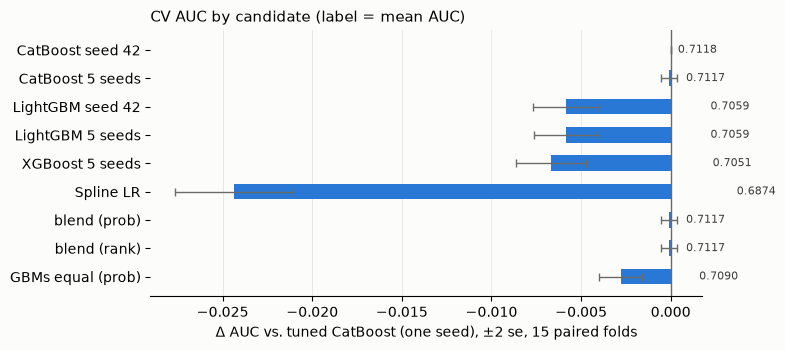

,auc_mean,Δ auc,se Δ,top_decile_prec
name,,,,
CatBoost seed 42,0.7118,+0.0000,0.0000,29.8%
CatBoost 5 seeds,0.7117,-0.0001,0.0002,29.9%
LightGBM seed 42,0.7059,-0.0058,0.0009,28.8%
LightGBM 5 seeds,0.7059,-0.0058,0.0009,28.8%
XGBoost 5 seeds,0.7051,-0.0067,0.0010,28.6%
Spline LR,0.6874,-0.0243,0.0016,26.5%
blend (prob),0.7117,-0.0001,0.0002,29.9%
blend (rank),0.7117,-0.0001,0.0002,29.9%
GBMs equal (prob),0.7090,-0.0028,0.0006,29.2%


In [8]:
allres = [res['CatBoost seed 42'], res['CatBoost 5 seeds'], res['LightGBM seed 42'], res['LightGBM 5 seeds'], res['XGBoost 5 seeds'],
          res['Spline LR']] + blends[1:]
tbl = paired(allres, 'CatBoost seed 42')
fig, ax = plt.subplots(figsize=(8, 3.6))
order = tbl.index[::-1]
ax.barh(order, tbl.loc[order, 'Δ auc'], xerr=2 * tbl.loc[order, 'se Δ'], color='#2a78d6', height=0.55,
        error_kw=dict(ecolor='#6b6a66', lw=1, capsize=3))
ax.axvline(0, color='#6b6a66', lw=1)
for i, n in enumerate(order):
    ax.text(max(tbl.loc[n, 'Δ auc'], 0) + 2 * tbl.loc[n, 'se Δ'] + 0.0004, i, f"{tbl.loc[n, 'auc_mean']:.4f}", va='center', fontsize=8, color='#3d3c39')
ax.set_xlabel('Δ AUC vs. tuned CatBoost (one seed), ±2 se, 15 paired folds'); ax.grid(axis='x', color='#e6e5e1', lw=0.6); ax.set_axisbelow(True)
for s in ('top', 'right', 'left'): ax.spines[s].set_visible(False)
ax.set_title('CV AUC by candidate (label = mean AUC)', loc='left', fontsize=11)
fig.patch.set_facecolor('#fcfcfb'); ax.set_facecolor('#fcfcfb'); fig.tight_layout()
fig.savefig('figures/05_ensemble_candidates.png', dpi=150, facecolor=fig.get_facecolor())
plt.show()
tbl.style.format(fmt)

**Reading:**
- **No model adds anything to CatBoost.** The weight search on the seed-0 folds put **100% on CatBoost** for both probability and rank averaging. An equal-weight GBM blend is clearly *worse* (−0.0027 ± 0.0007).
- **The other models are weaker, not different.** LightGBM (−0.0058) and XGBoost (−0.0067) are ~0.006 behind with rank correlation 0.97 to CatBoost: they see the same patterns, slightly less well. The spline LR *is* different (correlation 0.89) but much weaker (−0.024); its "different" errors are just errors.
- **Why CatBoost wins:** its edge over the other GBMs (~0.006) is large and stable across all 15 folds. The likely sources are ordered target statistics for the categoricals (state, carrier, package) and symmetric trees, which regularize well on noisy data.
- The spline LR (AUC 0.687, additive, no interactions) recovers ~93% of CatBoost's lift over random (0.187 vs 0.212 above 0.5). Most of the signal is in smooth main effects, which is good news for explaining the model.

## 6. Final fit and submissions
Each component is refit on all labeled quotes with its 5 seeds and trees × 1.2. Holdout predictions are combined with the chosen weights.
- With a **rank** blend, the blended percentile is mapped back to a probability with isotonic regression fitted on the OOF blend, so the submission is a calibrated probability (AUC is unchanged by this monotone map).
- Two files: seed-averaged tuned CatBoost alone, and the final model (if it differs). That's the day-1 pair from the plan.

OOF predictions of the final model are saved to `models/final_oof.parquet` for the presentation charts (lift, calibration).

In [9]:
SPEC = {'CatBoost 5 seeds': ('cb', TUNED['cb']['params'], TUNED['cb']['rounds']),
        'LightGBM 5 seeds': ('lgb', TUNED['lgb']['params'], TUNED['lgb']['rounds']),
        'XGBoost 5 seeds': ('xgb', XGB_P, xgb_cv['rounds']), 'Spline LR': ('lr', LR_P, 1)}

def holdout_pred(c):
    model, params, rounds = SPEC[c]
    if model == 'lr':
        return C.fit_full(lab, FEATS, 'lr', params)(hold)
    return np.mean([C.fit_full(lab, FEATS, model, params | {SEED_KEY[model]: s}, int(round(rounds * 1.2)))(hold) for s in MODEL_SEEDS], axis=0)

HP = {c: holdout_pred(c) for c in CAND if W.get(c, 0) > 0 or c == 'CatBoost 5 seeds'}
out = {'catboost_tuned5': C.write_submission('catboost_tuned5', hold, HP['CatBoost 5 seeds'])}
oof_final = (FINAL['oof_all']).mean(axis=0)
if use_blend:
    if HOW == 'prob':
        p_hold = sum(W[c] * HP[c] for c in W if W[c] > 0)
    else:
        rank_hold = sum(W[c] * pd.Series(HP[c]).rank(pct=True).to_numpy() for c in W if W[c] > 0)
        iso = IsotonicRegression(out_of_bounds='clip').fit(FINAL['oof_all'].ravel(), np.tile(y, 3))
        p_hold, oof_final = iso.predict(rank_hold), iso.predict(FINAL['oof_all'].ravel()).reshape(3, -1).mean(axis=0)
    out['blend'] = C.write_submission(f'blend_{HOW}', hold, p_hold)
else:
    p_hold = HP['CatBoost 5 seeds']
pd.DataFrame({'POLICY_ID': lab.POLICY_ID, 'y': y, 'oof_final': oof_final, 'oof_cb5': res['CatBoost 5 seeds']['oof_all'].mean(axis=0)}
             ).to_parquet('final_oof.parquet', index=False)
json.dump({'final': pick if use_blend else 'CatBoost 5 seeds', 'how': HOW, 'weights': {k: float(v) for k, v in W.items()},
           'cv_auc': FINAL['auc_mean'], 'cv_auc_se': FINAL['auc_se'], 'cv_top_decile_prec': FINAL['top_decile_prec'],
           'xgb_params': XGB_P, 'xgb_rounds': xgb_cv['rounds'], 'lr_params': LR_P, 'model_seeds': MODEL_SEEDS, 'round_scale': 1.2,
           'submissions': {k: str(v.name) for k, v in out.items()}}, open('ensemble.json', 'w'), indent=1, default=float)
print({k: v.name for k, v in out.items()})
pd.DataFrame({'holdout mean pred': [p_hold.mean()], 'labeled base rate': [y.mean()], 'OOF mean pred': [oof_final.mean()],
              'rank corr. final vs CatBoost (holdout)': [spearmanr(p_hold, HP['CatBoost 5 seeds'])[0]]}).round(4)

{'catboost_tuned5': 'catboost_tuned5_20261030.csv'}


,holdout mean pred,labeled base rate,OOF mean pred,rank corr. final vs CatBoost (holdout)
0,0.1114,0.1117,0.1111,1.0


In [10]:
# sanity: OOF calibration and decile lift of the final model (presentation versions come in the next notebook)
C.deciles(y, oof_final).style.format({'observed': '{:.1%}', 'predicted': '{:.1%}', 'lift': '{:.2f}', 'cum. capture': '{:.0%}'})

,quotes,converted,observed,predicted,lift,cum. capture
decile,,,,,,
1,2950,896.000000,30.4%,27.5%,2.72,27%
2,2949,537.000000,18.2%,18.0%,1.63,43%
3,2950,419.000000,14.2%,14.4%,1.27,56%
4,2949,375.000000,12.7%,12.0%,1.14,68%
5,2950,269.000000,9.1%,10.1%,0.82,76%
6,2949,271.000000,9.2%,8.6%,0.82,84%
7,2950,193.000000,6.5%,7.1%,0.59,90%
8,2949,152.000000,5.2%,5.8%,0.46,94%
9,2950,107.000000,3.6%,4.6%,0.32,98%


## Conclusions
- **Final model: tuned CatBoost, averaged over 5 seeds.** CV AUC **0.7117 ± 0.0036**, top-decile precision **29.9%** (base rate 11.2%, so ~2.7× lift). Seed averaging doesn't raise AUC, but it makes holdout predictions steadier at no cost.
- **Ensembling didn't help.** XGBoost (tuned, 0.7051), LightGBM (0.7059) and spline LR (0.6874) all get zero blend weight; adding any of them lowers CV AUC.
- **Submission written:** `submissions/catboost_tuned5_20261030.csv` (7,375 rows; mean prediction 11.1%, matching the 11.2% base rate). No separate blend file, since the blend *is* CatBoost.
- **Saved:** `ensemble.json` (decision, weights, XGBoost/LR params), `final_oof.parquet` (OOF predictions for the presentation's lift and calibration charts), `figures/05_ensemble_candidates.png`.
- Overall progress on identical folds: untuned CatBoost 0.6986 → feature selection 0.7011 → `DRIVERS_PER_VEH` 0.7078 → tuning **0.7117**.

**Next (`06_final`):** presentation outputs: decile lift chart, calibration plot, SHAP summary and dependence plots for the key drivers, and holdout-style metrics.